#### **_AI Workflowws_**

- **_Prompt Chaining:_**
  - Sequential pipeline (Outline → Draft → Review).


In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from langchain_groq import ChatGroq


# Graph State
class State(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    final_joke: str


llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)


## Define Nodes
def generate_joke(state: State):
    """First LLM call to generate initial joke"""

    msg = llm.invoke(f"Write a short joke about {state['topic']}")
    return {"joke": msg.content}


def check_punchline(state: State):
    """Gate function to check if the joke has a punchline"""

    # Simple check - does the joke contain "?" or "!"
    if "?" in state["joke"] or "!" in state["joke"]:
        return "Pass"
    return "Fail"


def improve_joke(state: State):
    """Second LLM call to improve the joke"""

    msg = llm.invoke(f"Make this joke funnier by adding wordplay: {state['joke']}")
    return {"improved_joke": msg.content}


def polish_joke(state: State):
    """Third LLM call for final polish"""
    msg = llm.invoke(f"Add a surprising twist to this joke: {state['improved_joke']}")
    return {"final_joke": msg.content}

In [2]:
## Build Workflow
workflow = StateGraph(State)

## Add Nodes
workflow.add_node("generate_joke", generate_joke)
workflow.add_node("improve_joke", improve_joke)
workflow.add_node("polish_joke", polish_joke)

## Add edges to connect nodes
workflow.add_edge(START, "generate_joke")
workflow.add_conditional_edges(
    "generate_joke", check_punchline, {"Fail": "improve_joke", "Pass": END}
)
workflow.add_edge("improve_joke", "polish_joke")
workflow.add_edge("polish_joke", END)

chain = workflow.compile()

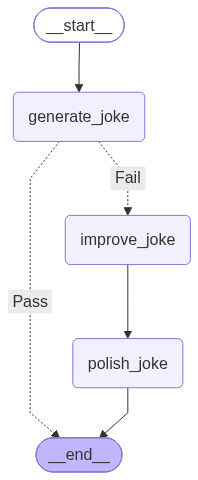

In [3]:
# Show workflow
display(Image(chain.get_graph().draw_mermaid_png()))

In [4]:
# Invoke
state = chain.invoke({"topic": "cats"})
print("Initial joke:")
print(state["joke"])
print("\n--- --- ---\n")
if "improved_joke" in state:
    print("Improved joke:")
    print(state["improved_joke"])
    print("\n--- --- ---\n")

    print("Final joke:")
    print(state["final_joke"])
else:
    print("Final joke:")
    print(state["joke"])

Initial joke:
Why did the cat bring a ladder to the bar?  
Because it heard the drinks were on the house! 🐾

--- --- ---

Final joke:
Why did the cat bring a ladder to the bar?  
Because it heard the drinks were on the house! 🐾


- **_Parallelization_**
  - Execute independent tasks at the same time.


In [5]:
# Graph state
class State(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str


# Nodes
def call_llm_1(state: State):
    """First LLM call to generate initial joke"""

    msg = llm.invoke(f"Write a joke about {state['topic']}")
    return {"joke": msg.content}


def call_llm_2(state: State):
    """Second LLM call to generate story"""

    msg = llm.invoke(f"Write a story about {state['topic']}")
    return {"story": msg.content}


def call_llm_3(state: State):
    """Third LLM call to generate poem"""

    msg = llm.invoke(f"Write a poem about {state['topic']}")
    return {"poem": msg.content}


def aggregator(state: State):
    """Combine the joke, story and poem into a single output"""

    combined = f"Here's a story, joke, and poem about {state['topic']}!\n\n"
    combined += f"STORY:\n{state['story']}\n\n"
    combined += f"JOKE:\n{state['joke']}\n\n"
    combined += f"POEM:\n{state['poem']}"
    return {"combined_output": combined}

In [6]:
# Build workflow
parallel_builder = StateGraph(State)

# Add nodes
parallel_builder.add_node("call_llm_1", call_llm_1)
parallel_builder.add_node("call_llm_2", call_llm_2)
parallel_builder.add_node("call_llm_3", call_llm_3)
parallel_builder.add_node("aggregator", aggregator)

# Add edges to connect nodes
parallel_builder.add_edge(START, "call_llm_1")
parallel_builder.add_edge(START, "call_llm_2")
parallel_builder.add_edge(START, "call_llm_3")
parallel_builder.add_edge("call_llm_1", "aggregator")
parallel_builder.add_edge("call_llm_2", "aggregator")
parallel_builder.add_edge("call_llm_3", "aggregator")
parallel_builder.add_edge("aggregator", END)
parallel_workflow = parallel_builder.compile()

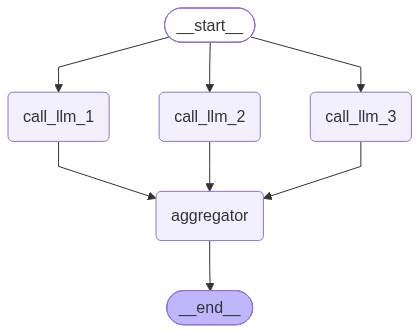

In [7]:
# Show workflow
display(Image(parallel_workflow.get_graph().draw_mermaid_png()))

In [8]:
# Invoke
state = parallel_workflow.invoke({"topic": "dogs"})
print(state["combined_output"])

Here's a story, joke, and poem about dogs!

STORY:
**The Map in the Mailbox**

On the quiet street of Willowbrook, the dogs of the neighborhood were as familiar as the old oak tree in the park. Max, a golden retriever with a coat that shone like sunrise, was the unofficial leader. Luna, a sleek black Labrador with a nose that could sniff out a treat from a mile away, was his right hand. Daisy, a sprightly beagle with a nose for adventure, and Toby, a tiny terrier who could fit into the smallest crevice, were the rest of the pack.

Every morning, the four of them would gather at the mailbox, a battered red postbox that had seen better days. They’d wag their tails, sniff the air, and wait for the mailman to drop the day's letters. It was a ritual that kept the dogs’ days in order, and it was also the place where their friendship began.

One crisp autumn afternoon, as the leaves turned amber and the wind carried the scent of pine, Max’s nose caught something unusual. He sniffed the mailbo

- **_Routing_**
  - Send requests to different experts based on the task.


In [9]:
from typing_extensions import Literal
from langchain.messages import HumanMessage, SystemMessage
from pydantic import BaseModel,Field


# Schema for structured output to use as routing logic
class Route(BaseModel):
    step: Literal["poem", "story", "joke"] = Field(
        None, description="The next step in the routing process"
    )


# Augment the LLM with schema for structured output
router = llm.with_structured_output(Route)


# State
class State(TypedDict):
    input: str
    decision: str
    output: str


# Nodes
def llm_call_1(state: State):
    """Write a story"""

    result = llm.invoke(state["input"])
    return {"output": result.content}


def llm_call_2(state: State):
    """Write a joke"""

    result = llm.invoke(state["input"])
    return {"output": result.content}


def llm_call_3(state: State):
    """Write a poem"""

    result = llm.invoke(state["input"])
    return {"output": result.content}

In [10]:
def llm_call_router(state: State):
    """Route the input to the appropriate node"""

    # Run the augmented LLM with structured output to serve as routing logic
    decision = router.invoke(
        [
            SystemMessage(
                content="Route the input to story, joke, or poem based on the user's request."
            ),
            HumanMessage(content=state["input"]),
        ]
    )

    return {"decision": decision.step}


# Conditional edge function to route to the appropriate node
def route_decision(state: State):
    # Return the node name you want to visit next
    if state["decision"] == "story":
        return "llm_call_1"
    elif state["decision"] == "joke":
        return "llm_call_2"
    elif state["decision"] == "poem":
        return "llm_call_3"


In [11]:
# Build workflow
router_builder = StateGraph(State)

# Add nodes
router_builder.add_node("llm_call_1", llm_call_1)
router_builder.add_node("llm_call_2", llm_call_2)
router_builder.add_node("llm_call_3", llm_call_3)
router_builder.add_node("llm_call_router", llm_call_router)

# Add edges to connect nodes
router_builder.add_edge(START, "llm_call_router")
router_builder.add_conditional_edges(
    "llm_call_router",
    route_decision,
    {  # Name returned by route_decision : Name of next node to visit
        "llm_call_1": "llm_call_1",
        "llm_call_2": "llm_call_2",
        "llm_call_3": "llm_call_3",
    },
)
router_builder.add_edge("llm_call_1", END)
router_builder.add_edge("llm_call_2", END)
router_builder.add_edge("llm_call_3", END)

# Compile workflow
router_workflow = router_builder.compile()

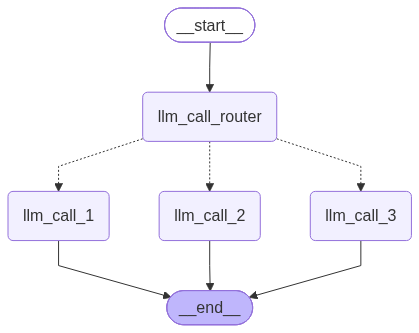

In [12]:
# Show the workflow
display(Image(router_workflow.get_graph().draw_mermaid_png()))

In [13]:
# Invoke
state = router_workflow.invoke({"input": "Write me a joke about cats"})
print(state["output"])

Why did the cat sit on the computer?

Because it wanted to keep an eye on the mouse! 🐱💻


In [14]:
from typing import Annotated, List
from pydantic import Field,BaseModel
import operator

# Schema for structured output to use in planning
class Section(BaseModel):
    name: str = Field(
        description="Name for this section of the report.",
    )
    description: str = Field(
        description="Brief overview of the main topics and concepts to be covered in this section.",
    )


class Sections(BaseModel):
    sections: List[Section] = Field(
        description="Sections of the report.",
    )

# Augment the LLM with schema for structured output
planner = llm.with_structured_output(Sections)

In [15]:
from langgraph.types import Send

# Graph state
class State(TypedDict):
    topic: str  # Report topic
    sections: list[Section]  # List of report sections
    completed_sections: Annotated[
        list, operator.add
    ]  # All workers write to this key in parallel
    final_report: str  # Final report


# Worker state
class WorkerState(TypedDict):
    section: Section
    completed_sections: Annotated[list, operator.add]


# Nodes
def orchestrator(state: State):
    """Orchestrator that generates a plan for the report"""

    # Generate queries
    report_sections = planner.invoke(
        [
            SystemMessage(content="Generate a plan for the report."),
            HumanMessage(content=f"Here is the report topic: {state['topic']}"),
        ]
    )

    return {"sections": report_sections.sections}


def llm_call(state: WorkerState):
    """Worker writes a section of the report"""

    # Generate section
    section = llm.invoke(
        [
            SystemMessage(
                content="Write a report section following the provided name and description. Include no preamble for each section. Use markdown formatting."
            ),
            HumanMessage(
                content=f"Here is the section name: {state['section'].name} and description: {state['section'].description}"
            ),
        ]
    )

    # Write the updated section to completed sections
    return {"completed_sections": [section.content]}


def synthesizer(state: State):
    """Synthesize full report from sections"""

    # List of completed sections
    completed_sections = state["completed_sections"]

    # Format completed section to str to use as context for final sections
    completed_report_sections = "\n\n---\n\n".join(completed_sections)

    return {"final_report": completed_report_sections}


# Conditional edge function to create llm_call workers that each write a section of the report
def assign_workers(state: State):
    """Assign a worker to each section in the plan"""

    # Kick off section writing in parallel via Send() API
    return [Send("llm_call", {"section": s}) for s in state["sections"]]


# Build workflow
orchestrator_worker_builder = StateGraph(State)

# Add the nodes
orchestrator_worker_builder.add_node("orchestrator", orchestrator)
orchestrator_worker_builder.add_node("llm_call", llm_call)
orchestrator_worker_builder.add_node("synthesizer", synthesizer)

# Add edges to connect nodes
orchestrator_worker_builder.add_edge(START, "orchestrator")
orchestrator_worker_builder.add_conditional_edges(
    "orchestrator", assign_workers, ["llm_call"]
)
orchestrator_worker_builder.add_edge("llm_call", "synthesizer")
orchestrator_worker_builder.add_edge("synthesizer", END)

# Compile the workflow
orchestrator_worker = orchestrator_worker_builder.compile()

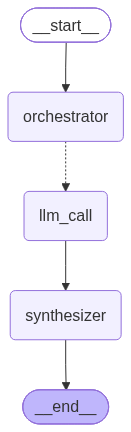

In [18]:
# Show the workflow
display(Image(orchestrator_worker.get_graph().draw_mermaid_png()))

In [19]:
# Graph state
class State(TypedDict):
    joke: str
    topic: str
    feedback: str
    funny_or_not: str


# Schema for structured output to use in evaluation
class Feedback(BaseModel):
    grade: Literal["funny", "not funny"] = Field(
        description="Decide if the joke is funny or not.",
    )
    feedback: str = Field(
        description="If the joke is not funny, provide feedback on how to improve it.",
    )


# Augment the LLM with schema for structured output
evaluator = llm.with_structured_output(Feedback)


# Nodes
def llm_call_generator(state: State):
    """LLM generates a joke"""

    if state.get("feedback"):
        msg = llm.invoke(
            f"Write a joke about {state['topic']} but take into account the feedback: {state['feedback']}"
        )
    else:
        msg = llm.invoke(f"Write a joke about {state['topic']}")
    return {"joke": msg.content}


def llm_call_evaluator(state: State):
    """LLM evaluates the joke"""

    grade = evaluator.invoke(f"Grade the joke {state['joke']}")
    return {"funny_or_not": grade.grade, "feedback": grade.feedback}


# Conditional edge function to route back to joke generator or end based upon feedback from the evaluator
def route_joke(state: State):
    """Route back to joke generator or end based upon feedback from the evaluator"""

    if state["funny_or_not"] == "funny":
        return "Accepted"
    elif state["funny_or_not"] == "not funny":
        return "Rejected + Feedback"


# Build workflow
optimizer_builder = StateGraph(State)

# Add the nodes
optimizer_builder.add_node("llm_call_generator", llm_call_generator)
optimizer_builder.add_node("llm_call_evaluator", llm_call_evaluator)

# Add edges to connect nodes
optimizer_builder.add_edge(START, "llm_call_generator")
optimizer_builder.add_edge("llm_call_generator", "llm_call_evaluator")
optimizer_builder.add_conditional_edges(
    "llm_call_evaluator",
    route_joke,
    {  # Name returned by route_joke : Name of next node to visit
        "Accepted": END,
        "Rejected + Feedback": "llm_call_generator",
    },
)

# Compile the workflow
optimizer_workflow = optimizer_builder.compile()

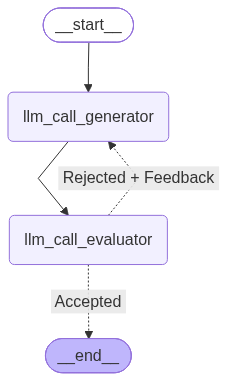

In [20]:
# Show the workflow
display(Image(optimizer_workflow.get_graph().draw_mermaid_png()))

In [21]:
# Invoke
state = optimizer_workflow.invoke({"topic": "Cats"})
print(state["joke"])

Why don’t cats play poker in the jungle?  

Because there are too many cheetahs!


### ***Employee Analytic Workflow***

In [1]:
from langgraph.graph import StateGraph,START,END 
from typing import TypedDict

## Defne State 
class EmployeeState(TypedDict):
     employee_name:str 
     monthly_salary:int
     working_days:int 
     completed_projects:int 
     yearly_salary:int 
     bonus_amount:int 
     project_status:str 
     summary:str 

In [2]:
## Calculate Yearly Salary 
def calculate_yearly_salary(state: EmployeeState):
    yearly_salary = state['monthly_salary'] * 12
  
    return {
        'yearly_salary': yearly_salary
}

## Calculate Bonus 
def calculate_bonus(state: EmployeeState):
    bonus_amount = state['monthly_salary'] * 2
    return {
        'bonus_amount': bonus_amount
}

## Project Evaluation 
def project_evaluation(state: EmployeeState):
    if state['completed_projects'] >= 5:
        status = 'Excellent'
    else:
        status = 'Average'

    return {
        'project_status': status
}

## Summary Node 
def summary(state: EmployeeState):
    summary_text = f"Employee {state['employee_name']} has a yearly salary of {state['yearly_salary']} and a bonus of {state['bonus_amount']}. Project status is {state['project_status']}."
    return {
        'summary': summary_text
    }

In [4]:
## Create Graph 
graph = StateGraph(EmployeeState)

graph.add_node('calculate_yearly_salary', calculate_yearly_salary)
graph.add_node('calculate_bonus', calculate_bonus)
graph.add_node('project_evaluation', project_evaluation)
graph.add_node('summary', summary)

# Add Edges
graph.add_edge(START, 'calculate_yearly_salary')
graph.add_edge(START, 'calculate_bonus')
graph.add_edge(START, 'project_evaluation')

graph.add_edge('calculate_yearly_salary', 'summary')
graph.add_edge('calculate_bonus', 'summary')
graph.add_edge('project_evaluation', 'summary')
graph.add_edge('summary', END)

workflow = graph.compile()

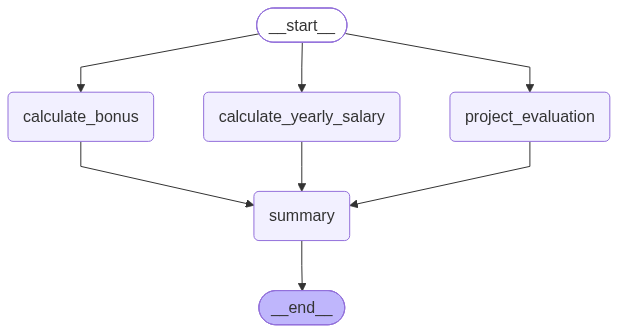

In [5]:
workflow

In [6]:
initial_state = {
    'employee_name': 'Ankit',
    'monthly_salary': 500000,
    'working_days': 26,
    'completed_projects': 7
}

# Run Workflow
result = workflow.invoke(initial_state)

In [7]:
result

{'employee_name': 'Ankit',
 'monthly_salary': 500000,
 'working_days': 26,
 'completed_projects': 7,
 'yearly_salary': 6000000,
 'bonus_amount': 1000000,
 'project_status': 'Excellent',
 'summary': 'Employee Ankit has a yearly salary of 6000000 and a bonus of 1000000. Project status is Excellent.'}

### ***Essay Generation Workflow***

In [8]:
from langgraph.graph import StateGraph,START,END 
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated
from pydantic import BaseModel,Field 
from dotenv import load_dotenv

import operator
load_dotenv()


llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)

In [9]:
# Deine Schema
class EvaluationSchema(BaseModel):
    feedback: str = Field(description='Detailed feedback for the essay')
    score: int = Field(description='Score out of 10', ge=0, le=10)

structured_model = llm.with_structured_output(EvaluationSchema)

In [10]:
essay = """Europe in the Age of AI: The Regulatory Superpower

As the world rushes headlong into the era of artificial intelligence, the European Union finds itself playing a unique and complex role. While the United States and China dominate the race to build the largest foundation models and hardware ecosystems, Europe has positioned itself as the global conscience of the AI age. For Europe, the challenge is not simply about technological supremacy, but about ensuring that AI aligns with democratic values, human rights, and environmental sustainability.

Europe's strengths lie in its deep academic traditions and its commitment to ethical frameworks. The continent is home to world-class research hubs, producing some of the leading minds in machine learning. Furthermore, Europe has a distinct advantage in industrial and B2B AI, driven by its manufacturing powerhouses in Germany, France, and Scandinavia. However, Europe’s most defining characteristic in this era is its regulatory muscle. With the passage of the AI Act, the EU has created the world’s first comprehensive legal framework for artificial intelligence, categorizing systems by risk and demanding unprecedented transparency from tech companies.

The European vision for AI is heavily focused on public good and sustainability. There is a strong push toward "Green AI," ensuring that the massive energy consumption of data centers aligns with the continent's aggressive climate goals. In healthcare, European nations are leveraging AI to advance precision medicine and streamline public health systems, while fiercely protecting patient data. Additionally, significant investments are being made to develop open-source, multilingual AI models that preserve Europe's rich linguistic diversity and reduce reliance on Silicon Valley.

Despite these noble ambitions, Europe faces substantial hurdles. The continent suffers from a severe lack of hyperscale tech companies and domestic cloud infrastructure, leaving it heavily dependent on foreign technology. This "compute deficit" is compounded by a fragmented venture capital market, which often struggles to commercialize academic breakthroughs. Consequently, Europe frequently experiences a brain drain, as its brightest AI researchers are lured away by the massive salaries and computing resources offered by American and Chinese tech giants.

The central tension for Europe is whether its regulatory approach will foster "trustworthy AI" or stifle homegrown innovation. Critics argue that stringent compliance burdens will price European startups out of the market, relegating the continent to being a consumer of foreign AI rather than a creator. Proponents, however, believe that by setting global ethical standards—the "Brussels Effect"—Europe will ultimately attract users and enterprises that demand secure, unbiased, and privacy-respecting technologies.

To succeed, Europe must balance its protective instincts with aggressive investment in digital infrastructure and innovation. It needs to foster a unified digital single market that allows startups to scale across borders effortlessly, while also forging strategic alliances to secure supply chains for critical hardware like semiconductors.

In conclusion, Europe in the age of AI represents a profound geopolitical experiment. It is testing whether a society can successfully govern exponential technology without sacrificing economic competitiveness. If Europe succeeds, it will provide a desperately needed global blueprint for human-centric AI; if it fails, it risks becoming an over-regulated museum in a world driven by algorithmic innovation."""

In [11]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
result = structured_model.invoke(prompt)

In [12]:
result

EvaluationSchema(feedback='The essay demonstrates a solid grasp of advanced vocabulary and complex sentence structures, reflecting a high level of language proficiency. The writer effectively employs varied syntax, including compound and complex sentences, and demonstrates a strong command of academic diction (e.g., "conscience," "hyperscale," "Brussels Effect"). The overall tone is formal and analytical, appropriate for an essay on policy and technology. However, there are a few areas that could be refined:\n\n1. **Consistency and Precision**: Some phrases are slightly awkward or imprecise. For example, "manufacturing powerhouses in Germany, France, and Scandinavia" could be more accurately phrased as "Germany, France, and the Scandinavian countries". The phrase "the continent suffers from a severe lack of hyperscale tech companies" could be tightened to "the continent lacks hyperscale tech companies".\n\n2. **Redundancy and Wordiness**: The essay occasionally repeats ideas or uses fi

In [13]:
result.feedback

'The essay demonstrates a solid grasp of advanced vocabulary and complex sentence structures, reflecting a high level of language proficiency. The writer effectively employs varied syntax, including compound and complex sentences, and demonstrates a strong command of academic diction (e.g., "conscience," "hyperscale," "Brussels Effect"). The overall tone is formal and analytical, appropriate for an essay on policy and technology. However, there are a few areas that could be refined:\n\n1. **Consistency and Precision**: Some phrases are slightly awkward or imprecise. For example, "manufacturing powerhouses in Germany, France, and Scandinavia" could be more accurately phrased as "Germany, France, and the Scandinavian countries". The phrase "the continent suffers from a severe lack of hyperscale tech companies" could be tightened to "the continent lacks hyperscale tech companies".\n\n2. **Redundancy and Wordiness**: The essay occasionally repeats ideas or uses filler words. Sentences such

In [14]:
result.score

8

In [15]:
## Define State 

class EssayState(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float

## Define Nodes 
def evaluate_language(state: EssayState):
    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}


def evaluate_analysis(state: EssayState):
    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}


def evaluate_thought(state: EssayState):
    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}


def final_evaluation(state: EssayState):
    # summary feedback
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    overall_feedback = llm.invoke(prompt).content
    # avg calculate
    avg_score = sum(state['individual_scores'])/len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}

In [16]:
graph = StateGraph(EssayState)

# add nodes
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)

# add edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')


graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')
graph.add_edge('final_evaluation', END)

workflow = graph.compile()

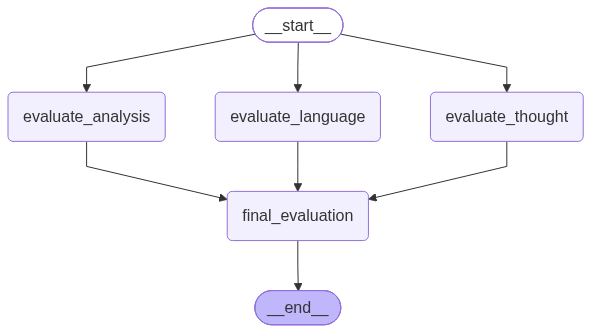

In [17]:
workflow

In [18]:
essay2 = """The United States in the Age of AI: The Infrastructure and Capital Superpower

As the world navigates the maturing landscape of artificial intelligence in 2026, the United States stands as the undisputed epicenter of the AI revolution. Driven by an ecosystem of hyperscalers, massive venture capital, and a fiercely competitive free market, the US has transitioned AI from a phase of speculative experimentation into the fundamental backbone of its digital and physical economy. However, the American approach to AI is no longer just a story of software and algorithms; it has evolved into the most capital-intensive infrastructure buildout in modern history, testing the physical limits of the nation's energy grid and resources.

The defining characteristic of the US AI strategy is its sheer scale and rapid commercialization. Silicon Valley and major tech hubs have pioneered the shift toward "Agentic AI" and "Physical AI." Intelligence is no longer confined to chatbots on a screen; autonomous agents are now orchestrating complex, end-to-end enterprise workflows, while advanced robotics powered by massive neural networks are redefining logistics and manufacturing floors. For American corporations, the current era marks a structural reorganization where operating models are being fundamentally redesigned around human-machine collaboration rather than merely automating legacy processes.

Yet, this relentless pursuit of scale has collided with physical reality, triggering an unprecedented energy reckoning. The US is building massive AI data center clusters that require gigawatts of continuous power. With data center electricity consumption projected to more than double in a span of just a few years, the nation is facing a severe power bottleneck. Connecting to the traditional grid now takes years, prompting hyperscalers to pioneer a "Bring Your Own Power" (BYOP) movement. Tech giants are directly funding behind-the-meter gas generation, reviving dormant nuclear facilities, and investing in advanced cooling technologies to fuel their server farms. AI infrastructure has become such a critical priority that it is increasingly viewed through the lens of national security, prompting aggressive federal action to expand the domestic supply of key electrical grid components.

On the policy front, the US government has dramatically accelerated its embrace of artificial intelligence. Moving away from more cautious regulatory frameworks, the focus has shifted entirely to removing barriers to innovation and ensuring tech sovereignty. The goal is clear: maintain a decisive strategic edge over global competitors, particularly China. Federal AI spending has skyrocketed into the tens of billions, dominated overwhelmingly by the Department of Defense, which views AI supremacy as a non-negotiable imperative for future military readiness, cybersecurity, and global diplomacy.

However, this hyper-accelerated growth is not without domestic friction. At the local level, the proliferation of massive data centers is creating tension in communities grappling with the environmental footprint of these facilities. Concerns over local electricity rate hikes, immense water usage in water-stressed regions, and the strain on existing utilities highlight the localized costs of a global tech race. Furthermore, while the US excels at rapid technological deployment, the corporate sector is experiencing a deep divide between companies effectively restructuring for an AI-native future and those struggling with high failure rates due to poor data quality and broken processes.

In conclusion, the United States in the age of AI represents a high-stakes, capital-fueled engine of exponential growth. It is a nation betting that its unmatched capacity for private investment, hardware innovation, and sheer ambition can overcome formidable physical bottlenecks. The American trajectory will ultimately determine whether a market-driven society can build and sustain the colossal physical infrastructure required to unlock the next frontier of human intelligence."""


In [19]:
intial_state = {
    'essay': essay2
}

result = workflow.invoke(intial_state)

In [20]:
result

{'essay': 'The United States in the Age of AI: The Infrastructure and Capital Superpower\n\nAs the world navigates the maturing landscape of artificial intelligence in 2026, the United States stands as the undisputed epicenter of the AI revolution. Driven by an ecosystem of hyperscalers, massive venture capital, and a fiercely competitive free market, the US has transitioned AI from a phase of speculative experimentation into the fundamental backbone of its digital and physical economy. However, the American approach to AI is no longer just a story of software and algorithms; it has evolved into the most capital-intensive infrastructure buildout in modern history, testing the physical limits of the nation\'s energy grid and resources.\n\nThe defining characteristic of the US AI strategy is its sheer scale and rapid commercialization. Silicon Valley and major tech hubs have pioneered the shift toward "Agentic AI" and "Physical AI." Intelligence is no longer confined to chatbots on a scr

### ***Content Moderation Workflow***